# Desarrollo Modelo - Estancia hospitalaria y terapia física

**Servicios de salud · Una clínica de rehabilitación**
Proyecto del primer corte · Modelos Lineales · Universidad de Manizales

_Desarrollado por: Ana Maria Rocha, Isabella Franco, Paula Elisabeth García_

---

### 1 · Contexto de los datos y el modelo:
Se realiza la presente consultoría a una Clínica de rehabilitación relacionada con la cantidad de días que se hopedan los pacientes egresados de cirugía de cadera debido a que se ha llegado al límite de camas. 

En un análisis previo, el comité de la clínica sacó la siguiente conclusión de cruzar los datos:

> Los pacientes a los que más fisioterapia les damos son los que más días se quedan hospitalizados. La fisioterapia está alargando la estancia.
>
> — La dirección médica

Debigo a este hallazgo, el comité propuso bajar el estándar de fisioterapia a solo dos sesiones semanales, a lo que el jefe de fisioterapia se opuso.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset, lilliefors
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

AZ, AC, GR, VD, RJ = '#1F2A44', '#3D5AFE', '#6B7280', '#0F7B4F', '#C0392B'
pd.set_option('display.width', 120)

datos = pd.read_csv('proyecto_1_clinica_estancia.csv')
print(datos.shape)
datos.head()

(160, 5)


,paciente,estancia_dias,sesiones_fisioterapia_semana,severidad_ingreso,edad_anios
0,P001,11.1,4.4,40.9,39
1,P002,1.7,3.5,23.5,47
2,P003,8.5,4.9,60.4,44
3,P004,15.0,6.3,62.4,51
4,P005,7.8,3.5,47.7,84


Se tienen registros de 160 pacientes para los cuales se tienen la siguiente información:
- Código del paciente.
- estancia_dias: los días de hospitalización del paciente, medida en días.
- sesiones_fisioterapia: sesiones de fisioterapia por semana medidas en sesiones/semana.
- severidad_ingreso: índice de severidad clínica al ingresar, medida en puntos del 0 al 100.
- edad_anios: edad del paciente, medidos en años.

---

### 2 · Desarrollo del problema y la decisión
El objetivo de esta consultoría es evaluar si la afirmación que se propuso en el comité de la clínica está sostenida y argumentada por los datos que se tienen en la base de datos que se recibe, ya que la decisión de reducir el estándar de fisioterapia a dos sesiones semanales, propuesta por el comité, va a afectar directamente a 1.900 pacientes al año y podría tener consecuencias en la tasa de reingresos a la clínica.

Esto se hará evaluando la correlación de las variables sesiones_fisioterapia_semana, severidad_ingreso y edad_anios (variables explicativas candidatas) para identificar cuáles de ellas tienen mayor asociación con la variable respuesta (estancia_dias), que es la que directamente describe el problema que se está presentando en la clínica. De esta manera, al modelar y encontrar la relación de las variables explicativas con la variable respuesta, se concluirá si la afirmación realizada por el comité de la clínica está sustentada por los datos o no, sin afirmar relaciones causales que estos no permiten demostrar.

Lo anterior se realizará por medio de un modelo de regresión lineal, inicialmente simple y posteriormente múltiple, debido a que permite evaluar la relación entre la variable dependiente (estancia_dias) y las variables independientes (sesiones_fisioterapia_semana, severidad_ingreso, edad_anios), comprobar si dicha relación puede representarse de forma lineal y estimar cómo cambia la estancia hospitalaria cuando varía una variable explicativa, manteniendo constantes las demás. Adicionalmente, permite interpretar los resultados en las unidades del problema y realizar predicciones de la estancia hospitalaria para nuevos pacientes.

---

### 2 · Exploración de los datos
Se desarrolla un análisis estadístico descriptivo, una matriz de correlación con su mapa de calor y un gráfico de correlación para conocer el comportamiento de los datos entregados en la base.

In [2]:
print("Análisis estadístico descriptivo:")
print(datos.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2).to_string())

Análisis estadístico descriptivo:
                              count   mean    std   min    50%   max
estancia_dias                 160.0   9.92   4.58   1.5   9.55  25.2
sesiones_fisioterapia_semana  160.0   4.69   1.37   1.7   4.80   8.6
severidad_ingreso             160.0  51.21  15.01  18.0  51.45  86.3
edad_anios                    160.0  57.92  13.81  25.0  58.00  93.0


 **Lectura de los descriptivos:** Se cuenta con 160 registros (pacientes hospitalizados egresados de cirugía de cadera) que en promedio se quedan 9.92 días hospitalizados en la clínica, se les realiza en promedio 4.69 sesiones de fisioterapia semanalmente, ingresan con una severidad en promedio de 51.21 puntos y su edad promedio es de 57.92 años. Al comparar el comportamiento de la media contra la mediana (50%), se puede concluir que tienen valores muy similares, lo cual sugiere que no existe una asimetría marcada en la distribución de las variables.

Matriz de correlación:
                              estancia_dias  sesiones_fisioterapia_semana  severidad_ingreso  edad_anios
estancia_dias                         1.000                         0.302              0.517      -0.051
sesiones_fisioterapia_semana          0.302                         1.000              0.776      -0.058
severidad_ingreso                     0.517                         0.776              1.000      -0.076
edad_anios                           -0.051                        -0.058             -0.076       1.000


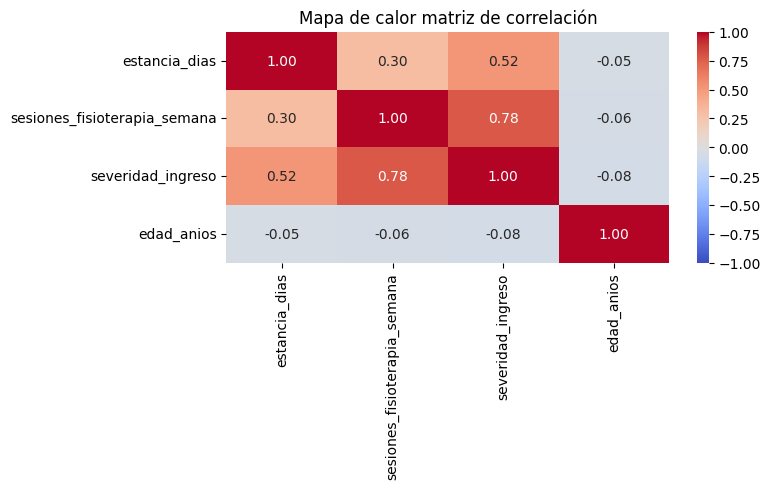

In [3]:
print("Matriz de correlación:")
corr = datos.select_dtypes('number').drop(columns='paciente_id', errors='ignore').corr()
print(corr.round(3).to_string())

plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Mapa de calor matriz de correlación')
plt.tight_layout()
plt.show()

**Lectura de la matriz:** Al evaluar la relación de las variables explicativas con la variable respuesta, se nota que severidad_ingreso supera a sesiones_fisioterapia_semana con una correlación positiva de 0.52 frente a 0.30, lo cual muestra un indicio para cuestionar la conclusión expuesta por el comité.

Adicionalmente, se considera relevante el comportamiento de sesiones_fisioterapia_semana y severidad_ingreso debido a la alta correlación positiva entre una y la otra (0.78), lo cual sugiere que los pacientes con mayor severidad al ingreso tienden a recibir más sesiones de fisioterapia y que esta relación puede afectar la interpretación de los coeficientes del modelo.

Por otro lado, la variable edad_anios tiene una correlación negativa con todas las variables: -0.05 con estancia_dias, -0.06 con sesiones_fisioterapia_semana y -0.08 con severidad_ingreso. Estas correlaciones son muy débiles, por lo que no muestran una relación lineal importante entre la edad y las demás variables. Sin embargo, esta correlación también puede estar siendo afectada por otras variables, lo cual deberá evaluarse posteriormente en el modelo múltiple.


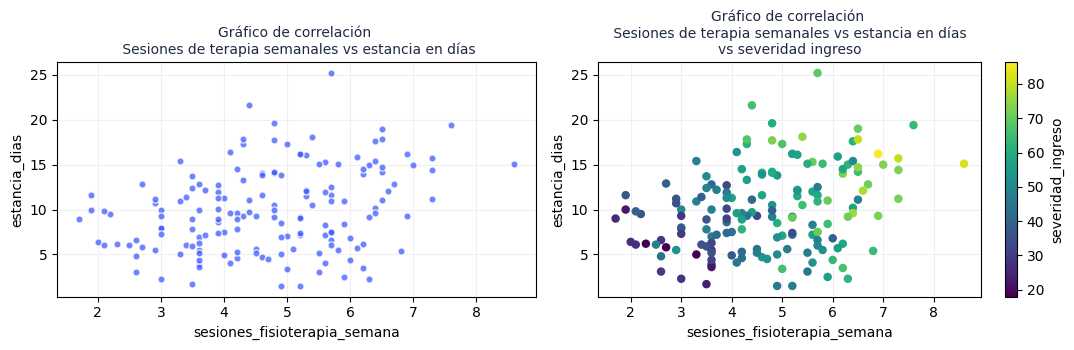

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(datos['sesiones_fisioterapia_semana'], datos['estancia_dias'], s=26, color=AC, alpha=.75, edgecolor='white')
ax[0].set_xlabel('sesiones_fisioterapia_semana'); ax[0].set_ylabel('estancia_dias')
ax[0].set_title('Gráfico de correlación \n Sesiones de terapia semanales vs estancia en días', fontsize=10, color=AZ)

sc = ax[1].scatter(datos['sesiones_fisioterapia_semana'], datos['estancia_dias'], c=datos['severidad_ingreso'], cmap='viridis', s=26)
plt.colorbar(sc, ax=ax[1], label='severidad_ingreso')
ax[1].set_xlabel('sesiones_fisioterapia_semana'); ax[1].set_ylabel('estancia_dias')
ax[1].set_title('Gráfico de correlación \n Sesiones de terapia semanales vs estancia en días \nvs severidad ingreso', fontsize=10, color=AZ)
for a in ax:
    a.grid(color='#EEF0F5'); a.set_axisbelow(True)
fig.tight_layout(); plt.show()

**Lectura del gráfico:** En el gráfico de la izquierda, se nota una correlación positiva entre la variable sesiones_fisioterapia_semana y la variable estancia_dias. Esta relación fue la que llevó al comité a interpretar que la primera era causante de la segunda, sin tener en cuenta que la correlación entre ambas no implica causalidad y que existen otras variables que pueden estar relacionadas con la estancia hospitalaria.

Por otro lado, en el gráfico de la derecha se incluyó, por medio de una escala de colores, la variable severidad_ingreso (que fue la que mayor correlación presentó con la variable respuesta en la matriz de correlación) y se puede observar que los pacientes con mayor puntaje de severidad tienden a recibir más sesiones de terapia semanal y a presentar mayores días de estancia en la clínica de rehabilitación. Esto sugiere que la severidad al ingreso podría estar relacionada con la asociación observada entre fisioterapia y estancia hospitalaria, por lo que será necesario analizar su efecto en el modelo de regresión lineal múltiple.

---

### 3 · El modelo de regresión líneal simple

Se desarrolla el modelo que respalda la afirmación del comité de la clinica: `estancia_dias ~ sesiones_fisioterapia_semana`.

                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            5.1808      1.239      4.183      0.000       2.735       7.627
sesiones_fisioterapia_semana     1.0106      0.253      3.989      0.000       0.510       1.511
R2 = 0.0915   R2 ajustado = 0.0857   s = 4.3828


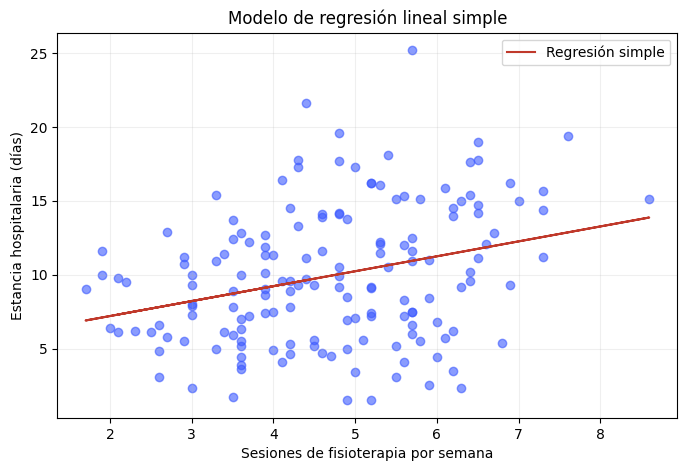

In [5]:
X_s = sm.add_constant(datos[['sesiones_fisioterapia_semana']])
simple = sm.OLS(datos['estancia_dias'], X_s).fit()
print(simple.summary().tables[1])
print(f'R2 = {simple.rsquared:.4f}   R2 ajustado = {simple.rsquared_adj:.4f}   s = {np.sqrt(simple.scale):.4f}')

plt.figure(figsize=(8, 5))

plt.scatter(datos['sesiones_fisioterapia_semana'],
            datos['estancia_dias'], color=AC, alpha=0.6)

plt.plot(datos['sesiones_fisioterapia_semana'],
         simple.fittedvalues, color=RJ, label='Regresión simple')

plt.xlabel('Sesiones de fisioterapia por semana')
plt.ylabel('Estancia hospitalaria (días)')
plt.title('Modelo de regresión lineal simple')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Analisis y conclusiones modelo regresión lineal simple:** se desarrolla el modelo de regresión lineal simple en el que solo se tiene en cuenta la variable sesiones_fisioterapia_semana (expresado en fórmula como *estancia_dias = 5.1808 + 1.0106 × sesiones_fisioterapia_semana*) para analizar los resultados estadísticos y evaluar qué tanto se encuentra sustentada la afirmación del comité en los datos. Los resultados son:

- Cuando un paciente tiene 0 sesiones de terapia, el modelo estima una estancia de 5.1808 días en la clínica; lo cual es alrededor de la mitad del promedio de días de estancia hospitalaria que muestra el resumen estadístico de los datos. Adicionalmente, al comparar pacientes que reciben una sesión más de fisioterapia por semana, el modelo estima en promedio 1.01 días adicionales de estancia hospitalaria, sin que esto implique una relación causal.

- Aunque la variable sesiones_fisioterapia_semana presenta significancia estadística (ya que tiene un p-value menor que 0.05), dicho modelo tiene un R² de 0.0915, lo cual indica que explica aproximadamente el 9.15 % de la variabilidad de los días de estancia hospitalaria. Adicionalmente, presenta un R² ajustado de 0.0857, lo que indica que, al considerar la cantidad de variables explicativas, se explica aproximadamente el 8.57 % de dicha variabilidad.

- Por otro lado, el modelo presenta un error típico (s) de 4.3828 días, lo cual indica que los valores reales de estancia hospitalaria presentan una dispersión residual típica de aproximadamente 4.38 días respecto a los valores estimados por el modelo. Esto muestra que todavía existe una variabilidad considerable que el modelo no logra explicar.

- Adicionalmente, el intervalo de confianza del 95 % para la pendiente está entre 0.510 y 1.511 días por cada sesión semanal adicional de fisioterapia. Como este intervalo no incluye el cero, se respalda estadísticamente la existencia de una asociación lineal positiva entre ambas variables.

Por lo anterior, aunque existe una relación estadísticamente significativa entre las sesiones de fisioterapia y los días de estancia hospitalaria, el modelo explica muy poco los datos, por lo que se concluye que no es un modelo suficientemente completo para tomar decisiones a partir de él sin considerar otras variables que puedan estar relacionadas con la estancia hospitalaria.

---

### 4 · El modelo de regresión lineal múltiple
Se realiza una réplica del modelo anterior al cual se le incluye la variable severidad_ingreso con el objetivo de analizar la influencia que tiene esta sobre el modelo desde los resultados estadísticos. Se espera que el coeficiente de la variable sesiones_fisioterapia baje y la nueva variable tome influencia en el modelo ya que, como se vio en el gráfico de correlación en el punto 2 donde se incluían las tres variables, esta nueva variable tiene la misma tendencia.

In [6]:
X_m = sm.add_constant(datos[['sesiones_fisioterapia_semana', 'severidad_ingreso']])
multiple = sm.OLS(datos['estancia_dias'], X_m).fit()
print(multiple.summary().tables[1])
print(f'R2 = {multiple.rsquared:.4f}   R2 ajustado = {multiple.rsquared_adj:.4f}   s = {np.sqrt(multiple.scale):.4f}')

vif = pd.DataFrame({'variable': ['sesiones_fisioterapia_semana', 'severidad_ingreso'],
                    'VIF': [variance_inflation_factor(X_m.values, i) for i in (1, 2)]})
print()
print(vif.round(3).to_string(index=False))

                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            2.7241      1.158      2.353      0.020       0.438       5.010
sesiones_fisioterapia_semana    -0.8300      0.356     -2.331      0.021      -1.533      -0.127
severidad_ingreso                0.2167      0.033      6.659      0.000       0.152       0.281
R2 = 0.2916   R2 ajustado = 0.2826   s = 3.8824

                    variable   VIF
sesiones_fisioterapia_semana 2.517
           severidad_ingreso 2.517


**Analisis y conclusiones resultados modelo regresión lineal múltiple:** se desarrolla el modelo de regresión lineal múltiple incluyendo las variables sesiones_fisioterapia_semana y severidad_ingreso para evaluar cómo cambia la relación con estancia_dias al tener en cuenta la severidad de los pacientes representado por la siguiente fórmula: *estancia_dias = 2.7241 - 0.8300 × sesiones_fisioterapia_semana + 0.2167 × severidad_ingreso* con los siguientes resultados:
- Cuando un paciente tiene 0 sesiones de terapia, el modelo estima una estancia de 2.7241 días en la clínica, valor que disminuye comparado con el modelo anterior.

- Por otro lado, el modelo estima que a igual severidad de ingreso, los pacientes que reciben una sesión adicional de fisioterapia semanal presentan en promedio 0.83 días menos de estancia hospitalaria; y a igual cantidad de sesiones de fisioterapia, los pacientes que presentan un punto adicional de severidad al ingreso tienen en promedio 0.2167 días más de estancia hospitalaria.

Teniendo en cuenta que tanto el modelo como ambas variables presentan significancia estadística (p-value menor que 0.05) y un intervalo de confianza que no pasa por 0, se interpreta que que existe evidencia de una asociación entre las variables y los días de estancia hospitalaria.

coef. de sesiones_fisioterapia_semana en el modelo múltiple ....... -0.8300
coef. de severidad_ingreso x pendiente auxiliar ....... +1.8406
----------------------------------------------------------
suma ..................................... +1.0106
pendiente del modelo simple .............. +1.0106


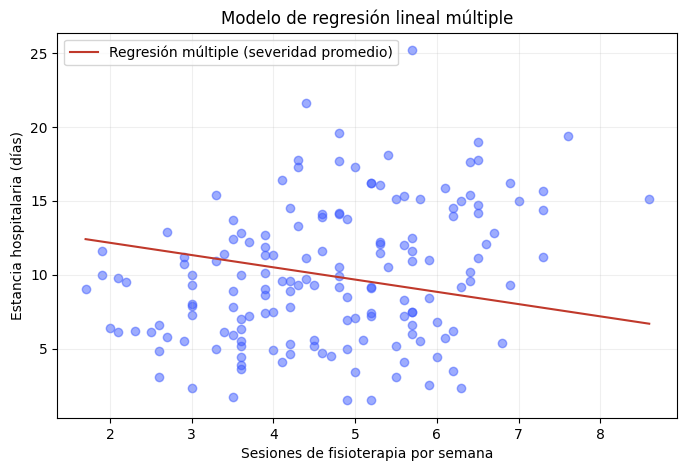

In [7]:
# la cuenta que explica el cambio de la pendiente
aux = sm.OLS(datos['severidad_ingreso'], sm.add_constant(datos[['sesiones_fisioterapia_semana']])).fit()
gamma = aux.params.iloc[1]
reconstruida = multiple.params.iloc[1] + multiple.params.iloc[2] * gamma

print(f'coef. de sesiones_fisioterapia_semana en el modelo múltiple ....... {multiple.params.iloc[1]:+.4f}')
print(f'coef. de severidad_ingreso x pendiente auxiliar ....... {multiple.params.iloc[2] * gamma:+.4f}')
print(f'{"-"*58}')
print(f'suma ..................................... {reconstruida:+.4f}')
print(f'pendiente del modelo simple .............. {simple.params.iloc[1]:+.4f}')

#Gráfico
sesiones = np.linspace(datos['sesiones_fisioterapia_semana'].min(),
                       datos['sesiones_fisioterapia_semana'].max(), 100)

severidad_media = datos['severidad_ingreso'].mean()

estancia_pred = (multiple.params['const']
                + multiple.params['sesiones_fisioterapia_semana'] * sesiones
                + multiple.params['severidad_ingreso'] * severidad_media)

plt.figure(figsize=(8, 5))

plt.scatter(datos['sesiones_fisioterapia_semana'],
            datos['estancia_dias'], color=AC, alpha=0.5)

plt.plot(sesiones, estancia_pred, color=RJ,
         label='Regresión múltiple (severidad promedio)')

plt.xlabel('Sesiones de fisioterapia por semana')
plt.ylabel('Estancia hospitalaria (días)')
plt.title('Modelo de regresión lineal múltiple')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Análisis cambio de pendiente:** 

Al comparar los modelos, se observa que la pendiente de sesiones_fisioterapia_semana pasó de +1.0106 en el modelo simple a -0.8300 en el múltiple. Esto se debe a que inicialmente no se consideraba la severidad de ingreso, variable que presenta una relación positiva tanto con las sesiones de fisioterapia como con la estancia hospitalaria.

Al realizar la reconstrucción de la pendiente, se obtiene: *1.0106 ≈ -0.8300 + (0.2167 × 8.4950)*

Esto demuestra que el modelo simple estaba incluyendo la asociación relacionada con la severidad. Al incorporar esta variable en el modelo múltiple, se encuentra que, a igual severidad de ingreso, una sesión adicional de fisioterapia semanal está asociada con 0.83 días menos de estancia hospitalaria, lo cual también se refleja en la pendiente negativa del gráfico.

**Conclusiones generales del modelo múltiple:**

El modelo de regresión lineal múltiple presenta un R² ajustado de 28.26 %, mejorando frente al 8.57 % del modelo de regresión lineal simple, lo que quiere decir que este es un poco más cercano a la realidad de los datos; adicionalmente, el error típico disminuyó de 4.38 a 3.88 días, lo que indica una menor dispersión de los datos respecto a las estimaciones. Por otro lado, los VIF de 2.52 muestran que existe correlación entre las variables explicativas, pero no una multicolinealidad severa.

Por lo anterior, se concluye que la severidad de ingreso es una variable importante para explicar la estancia hospitalaria y que los resultados continuan cuestionando la afirmación del comité, ya que al considerar la severidad, una mayor cantidad de fisioterapia se asocia con menos días de hospitalización (como lo muestra el cambio en la pendiente) sin esto implicar explicación de causalidad de ninguna de las variables explicativas a la variable respuesta. 

---

## 5 · Observaciones influyentes
Se generan los umbrales de referencia de los indicadores leverage, distancia de cook y DFBeta para identificar observaciones que superen estos humbrales y por tal deban ser revisadas y cuestionadas por eficiencia del modelo.

In [8]:
inf = multiple.get_influence()
n, p = len(datos), 3
diag = pd.DataFrame({
    'h': inf.hat_matrix_diag,
    'estudentizado': inf.resid_studentized_external,
    'cook': inf.cooks_distance[0],
    'dfbeta': inf.dfbetas[:, 1]}, index=datos.index)

u_h, u_cook, u_dfb = 2 * p / n, 4 / n, 2 / np.sqrt(n)
print(f'umbrales:  2p/n = {u_h:.4f}    4/n = {u_cook:.4f}    2/raiz(n) = {u_dfb:.4f}')
print(f'Σh = {diag.h.sum():.4f}  (tiene que dar p = {p})')
print()
print('superan palanca:', list(diag.index[diag.h > u_h])[:12])
print('superan Cook:   ', list(diag.index[diag.cook > u_cook])[:12])
diag.sort_values('cook', ascending=False).head(6).round(4)

umbrales:  2p/n = 0.0375    4/n = 0.0250    2/raiz(n) = 0.1581
Σh = 3.0000  (tiene que dar p = 3)

superan palanca: [13, 32, 41, 51, 76, 85, 96, 117, 122, 124, 141, 154]
superan Cook:    [6, 16, 96, 124, 138, 142, 156, 158]


,h,estudentizado,cook,dfbeta
124,0.0449,2.4586,0.0919,0.4662
158,0.0155,3.2852,0.0533,-0.0754
142,0.0280,2.1631,0.0439,-0.2730
16,0.0322,1.8592,0.0378,0.3045
96,0.0383,-1.6875,0.0374,0.3075
156,0.0168,-2.4961,0.0344,0.1698


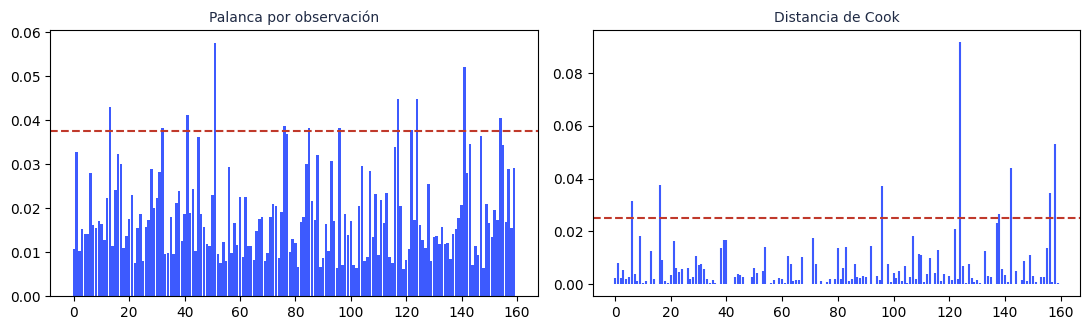

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(diag.index, diag.h, color=AC, width=.9)
ax[0].axhline(u_h, color=RJ, ls='--'); ax[0].set_title('Palanca por observación', fontsize=10, color=AZ)
ax[1].vlines(diag.index, 0, diag.cook, color=AC)
ax[1].axhline(u_cook, color=RJ, ls='--'); ax[1].set_title('Distancia de Cook', fontsize=10, color=AZ)
fig.tight_layout(); plt.show()

**Lectura de las observaciones influyentes:** al evaluar los resultados, se encuentran 12 pacientes que superan el umbral de leverage (0.0375) y 8 que superan el umbral de Cook (0.0250), lo cual indica que existen observaciones con características diferentes al resto y otras que pueden estar influyendo en los resultados del modelo, de estas observaciones se destaca el paciente P125 (índice 124) porque, además del humbral de la distancia de cook, supera los umbrales de leverage y DFBETA, por lo que el primer ajuste que se desarrollará al modelo para ser evaluado será la eliminación de este registro del modelo.

De igual manera, se observan entre los resultados que superan los umbrales que los pacientes P95, P142 y P159 (correspondientes a los índices 96, 141 y 158) también presentan alto nivel de superación del umbral por lo que el segundo modelo a desarrollar para la evaluación de ajuste del modelo incluirá la eliminación de estos registros también.

In [10]:
multiple_sin_124 = sm.OLS(
    datos['estancia_dias'].drop(index=124),
    X_m.drop(index=124)
).fit()

print('Modelo sin el registro 124')
print(multiple_sin_124.summary().tables[1])
print(f'R2 = {multiple_sin_124.rsquared:.4f}   '
      f'R2 ajustado = {multiple_sin_124.rsquared_adj:.4f}   '
      f's = {np.sqrt(multiple_sin_124.scale):.4f}')

Modelo sin el registro 124
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            3.0090      1.145      2.627      0.009       0.747       5.271
sesiones_fisioterapia_semana    -0.9934      0.357     -2.785      0.006      -1.698      -0.289
severidad_ingreso                0.2249      0.032      6.985      0.000       0.161       0.289
R2 = 0.2991   R2 ajustado = 0.2901   s = 3.8215


In [11]:
multiple_sin_4 = sm.OLS(
    datos['estancia_dias'].drop(index=[124, 96, 141, 158]),
    X_m.drop(index=[124, 96, 141, 158])
).fit()

print('Modelo sin los registros 124, 96, 141 y 158')
print(multiple_sin_4.summary().tables[1])
print(f'R2 = {multiple_sin_4.rsquared:.4f}   '
      f'R2 ajustado = {multiple_sin_4.rsquared_adj:.4f}   '
      f's = {np.sqrt(multiple_sin_4.scale):.4f}')

Modelo sin los registros 124, 96, 141 y 158
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            3.3621      1.109      3.032      0.003       1.171       5.553
sesiones_fisioterapia_semana    -1.1100      0.358     -3.102      0.002      -1.817      -0.403
severidad_ingreso                0.2278      0.032      7.077      0.000       0.164       0.291
R2 = 0.3043   R2 ajustado = 0.2952   s = 3.6849


In [12]:
modelos = {
    'Original': multiple,
    'Sin 124': multiple_sin_124,
    'Sin 124, 96, 141 y 158': multiple_sin_4
}

filas = []

for nombre, modelo in modelos.items():
    filas.append({
        'Modelo': nombre,
        'Intercepto': modelo.params['const'],
        'sesiones_fisioterapia_semana':
            modelo.params['sesiones_fisioterapia_semana'],
        'severidad_ingreso':
            modelo.params['severidad_ingreso'],
        'R2': modelo.rsquared,
        'R2 ajustado': modelo.rsquared_adj,
        's': np.sqrt(modelo.scale)
    })

comparacion = pd.DataFrame(filas).set_index('Modelo')
print(comparacion.round(4).to_string())

                        Intercepto  sesiones_fisioterapia_semana  severidad_ingreso      R2  R2 ajustado       s
Modelo                                                                                                          
Original                    2.7241                       -0.8300             0.2167  0.2916       0.2826  3.8824
Sin 124                     3.0090                       -0.9934             0.2249  0.2991       0.2901  3.8215
Sin 124, 96, 141 y 158      3.3621                       -1.1100             0.2278  0.3043       0.2952  3.6849


**Análisis y comparación de los modelos:** Al comparar los tres modelos, se observa que en el modelo donde se retiran las cuatro observaciones el R² aumenta a 30.43 % (frente al 29.91 % del modelo sin el registro 124 y al 29.16 % del original), lo que indica un mayor ajuste a los datos utilizados en cada modelo. Adicionalmente, el R² ajustado aumenta a 29.52 % frente a 29.01 % y 28.26 %, respectivamente; por otro lado, el error típico disminuye a 3.6849 días (frente a 3.8215 y 3.8824 días, respectivamente), lo que indica una menor dispersión de los datos respecto a las estimaciones.

Los tres modelos mantienen significancia estadística global, con valores p menores que 0.001. En el escenario sin las cuatro observaciones, ambos coeficientes también son significativos: sesiones_fisioterapia_semana presenta un valor p de 0.0023 y un intervalo de confianza del 95 % entre −1.8170 y −0.4030; severidad_ingreso presenta un valor p menor que 0.001 y un intervalo entre 0.1642 y 0.2914, cabe aclarar que inguno de los intervalos incluye el cero lo cual soporta la significancia de estas en el modelo.

Al evaluar el cambio en el coeficiente de sesiones_fisioterapia_semana, se observa que pasa de −0.8300 en el modelo original a −0.9934 sin el registro 124 y a −1.1100 sin las cuatro observaciones. Esto muestra que los registros evaluados influyen en la magnitud de la asociación, aunque se mantiene su dirección: a igual severidad de ingreso, una mayor cantidad de sesiones de fisioterapia semanal se asocia con menos días de hospitalización lo que es congruente con conclusiones de pasos anteriores sobre el poco argumento basados en los datos que tiene la afirmación presentada por el cómite de la clínica.



---

## 6 · Supuestos y diagnóstico

--- Pruebas modelo múltiple ---
  RESET (forma)            p =  0.2996   pasa
  Breusch-Pagan (var.)     p =  0.0037   NO PASA
  White (var.)             p =  0.0113   NO PASA
  Shapiro-Wilk (norm.)     p =  0.7750   pasa
  Lilliefors (norm.)       p =  0.6847   pasa
  Durbin-Watson                 2.0404   (cerca de 2 está bien)


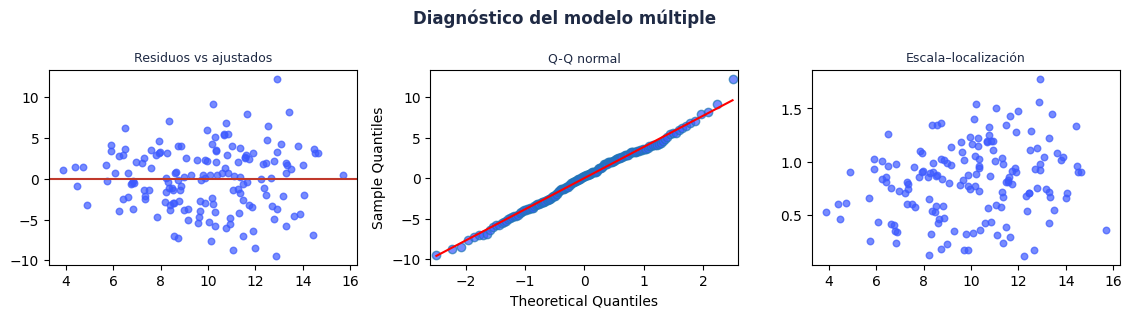

                                beta  SE clásico  SE HC3
const                         2.7241      1.1575  0.9378
sesiones_fisioterapia_semana -0.8300      0.3560  0.3930
severidad_ingreso             0.2167      0.0325  0.0340


In [13]:
def revisar(modelo, X, nombre):
    e = modelo.resid
    pruebas = {
        'RESET (forma)':        linear_reset(modelo, power=2, use_f=True).pvalue,
        'Breusch-Pagan (var.)': het_breuschpagan(e, X)[1],
        'White (var.)':         het_white(e, X)[1],
        'Shapiro-Wilk (norm.)': stats.shapiro(e).pvalue,
        'Lilliefors (norm.)':   lilliefors(e, dist='norm')[1]}
    print(f'--- {nombre} ---')
    for k, v in pruebas.items():
        print(f'  {k:24s} p = {v:7.4f}   {"pasa" if v > .05 else "NO PASA"}')
    print(f'  {"Durbin-Watson":24s}     {durbin_watson(e):7.4f}   (cerca de 2 está bien)')

revisar(multiple, X_m, 'Pruebas modelo múltiple')

#Gráfico
def panel(modelo, titulo):
    e, yhat = modelo.resid, modelo.fittedvalues
    fig, ax = plt.subplots(1, 3, figsize=(11.4, 3.2))
    ax[0].scatter(yhat, e, s=22, color=AC, alpha=.7); ax[0].axhline(0, color=RJ)
    ax[0].set_title('Residuos vs ajustados', fontsize=9, color=AZ)
    sm.qqplot(e, line='s', ax=ax[1], markerfacecolor=AC, alpha=.7)
    ax[1].set_title('Q-Q normal', fontsize=9, color=AZ)
    ax[2].scatter(yhat, np.sqrt(np.abs(e / np.sqrt(modelo.mse_resid))), s=22, color=AC, alpha=.7)
    ax[2].set_title('Escala–localización', fontsize=9, color=AZ)
    fig.suptitle(titulo, color=AZ, fontweight='bold'); fig.tight_layout(); plt.show()

panel(multiple, 'Diagnóstico del modelo múltiple')

# si falla la varianza, errores robustos (ojo con use_t)
rob = multiple.get_robustcov_results(cov_type='HC3', use_t=True)
print(pd.DataFrame({'beta': multiple.params.values,
                    'SE clásico': multiple.bse.values,
                    'SE HC3': rob.bse}, index=X_m.columns).round(4).to_string())

**Análisis de los supuestos del modelo original:** al evaluar los resultados, RESET presenta un valor p de 0.2996, por lo que no se encuentra evidencia suficiente para cuestionar la forma del modelo evaluada. Por otro lado, Breusch-Pagan y White presentan valores p de 0.0037 y 0.0113, respectivamente, lo que indica que existe heterocedasticidad: los errores al estimar los días de hospitalización no tienen la misma dispersión para todos los pacientes, comportamiento que también se aprecia en los gráficos.

Shapiro-Wilk y Lilliefors presentan valores p de 0.7750 y 0.6847, por lo que no se rechaza la normalidad de los errores, lo cual coincide con la alineación aproximada del gráfico Q-Q. Durbin-Watson obtiene 2.0404, sin una señal marcada de autocorrelación según el orden de los registros. Al aplicar HC3, los errores estándar de fisioterapia y severidad aumentan de 0.3560 a 0.3930 y de 0.0325 a 0.0340, respectivamente. Esto indica mayor incertidumbre en estos coeficientes que la expresada por el cálculo clásico, sin cambiar la ecuación ni las estimaciones del modelo.

--- MODELO SIN 124 ---
  RESET (forma)            p =  0.2073   pasa
  Breusch-Pagan (var.)     p =  0.0067   NO PASA
  White (var.)             p =  0.0197   NO PASA
  Shapiro-Wilk (norm.)     p =  0.6467   pasa
  Lilliefors (norm.)       p =  0.3641   pasa
  Durbin-Watson                 2.0838   (cerca de 2 está bien)


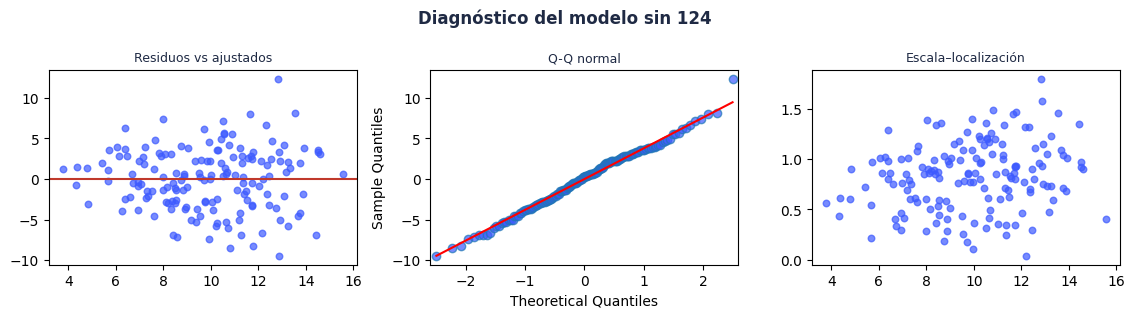

                                beta  SE clásico  SE HC3
const                         3.0090      1.1452  0.9090
sesiones_fisioterapia_semana -0.9934      0.3567  0.3750
severidad_ingreso             0.2249      0.0322  0.0336


In [14]:
revisar(multiple_sin_124, X_m.drop(index=124), 'MODELO SIN 124')

panel(multiple_sin_124, 'Diagnóstico del modelo sin 124')

rob_sin_124 = multiple_sin_124.get_robustcov_results(
    cov_type='HC3', use_t=True
)

print(pd.DataFrame({
    'beta': multiple_sin_124.params.values,
    'SE clásico': multiple_sin_124.bse.values,
    'SE HC3': rob_sin_124.bse
}, index=X_m.columns).round(4).to_string())

**Análisis de los supuestos del modelo sin el registro 124:** RESET presenta un valor p de 0.2073, por lo que no se encuentra evidencia suficiente para cuestionar la forma del modelo evaluada. Sin embargo, Breusch-Pagan y White presentan valores p de 0.0067 y 0.0197, respectivamente, lo que muestra que retirar este registro no elimina la heterocedasticidad. Los gráficos mantienen una dispersión desigual de los errores, por lo que la precisión al estimar la estancia continúa variando entre pacientes.

Shapiro-Wilk y Lilliefors presentan valores p de 0.6467 y 0.3641, por lo que no se rechaza la normalidad de los errores, comportamiento consistente con el gráfico Q-Q. Durbin-Watson obtiene 2.0838, sin una señal marcada de autocorrelación según el orden de los registros. Al aplicar HC3, los errores estándar de fisioterapia y severidad aumentan de 0.3567 a 0.3750 y de 0.0322 a 0.0336, respectivamente. Por tanto, aunque se retira una observación influyente, permanece el problema de varianza y la necesidad de ajustar la estimación de la incertidumbre de los coeficientes.

--- MODELO SIN CUATRO OBSERVACIONES ---
  RESET (forma)            p =  0.2336   pasa
  Breusch-Pagan (var.)     p =  0.0069   NO PASA
  White (var.)             p =  0.0070   NO PASA
  Shapiro-Wilk (norm.)     p =  0.4145   pasa
  Lilliefors (norm.)       p =  0.2441   pasa
  Durbin-Watson                 2.0598   (cerca de 2 está bien)


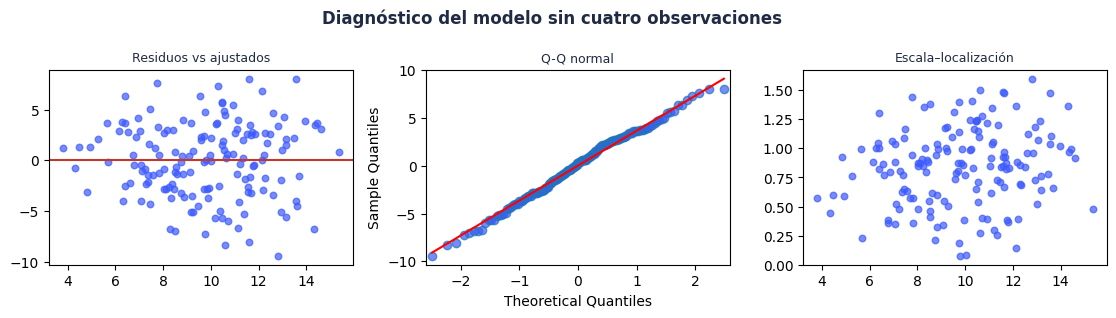

                                beta  SE clásico  SE HC3
const                         3.3621      1.1090  0.8815
sesiones_fisioterapia_semana -1.1100      0.3579  0.3891
severidad_ingreso             0.2278      0.0322  0.0341


In [15]:
revisar(
    multiple_sin_4,
    X_m.drop(index=[124, 96, 141, 158]),
    'MODELO SIN CUATRO OBSERVACIONES'
)

panel(multiple_sin_4, 'Diagnóstico del modelo sin cuatro observaciones')

rob_sin_4 = multiple_sin_4.get_robustcov_results(
    cov_type='HC3', use_t=True
)

print(pd.DataFrame({
    'beta': multiple_sin_4.params.values,
    'SE clásico': multiple_sin_4.bse.values,
    'SE HC3': rob_sin_4.bse
}, index=X_m.columns).round(4).to_string())

**Análisis de los supuestos del modelo sin las cuatro observaciones:** RESET presenta un valor p de 0.2336, por lo que no se encuentra evidencia suficiente para cuestionar la forma del modelo evaluada. Por otro lado, Breusch-Pagan y White presentan valores p de 0.0069 y 0.0070, respectivamente, mostrando que la heterocedasticidad permanece. Aunque en los gráficos desaparece el residuo positivo más extremo, los errores continúan teniendo una dispersión desigual entre pacientes.

Shapiro-Wilk y Lilliefors presentan valores p de 0.4145 y 0.2441, por lo que no se rechaza la normalidad de los errores, lo cual coincide con la alineación aproximada del gráfico Q-Q. Durbin-Watson obtiene 2.0598, sin una señal marcada de autocorrelación según el orden de los registros. Al aplicar HC3, los errores estándar de fisioterapia y severidad aumentan de 0.3579 a 0.3891 y de 0.0322 a 0.0341, respectivamente. Por lo anterior, la mejora del ajuste encontrada al retirar estas observaciones no significa que se hayan resuelto los problemas de diagnóstico, ya que continúa siendo necesario considerar la varianza desigual al evaluar la precisión de los coeficientes.

**Conclusión de la comparación de los supuestos y diagnóstico:** al comparar los tres modelos, se observa que retirar las cuatro observaciones mejora moderadamente el ajuste, aumentando el R² de 29.16 % a 30.43 % y disminuyendo el error típico de 3.8824 a 3.6849 días. Sin embargo, los tres modelos continúan presentando heterocedasticidad, por lo que retirar estos registros no resuelve el problema de varianza identificado.

Adicionalmente, no se encuentra evidencia suficiente para cuestionar la forma del modelo evaluada ni rechazar la normalidad de los errores en ninguno de los escenarios. Teniendo en cuenta que tampoco se identifican errores de registro o información que justifique excluir a estos pacientes, se decide continuar con el modelo múltiple original, conservando las 160 observaciones y utilizando errores estándar robustos HC3 para evaluar la incertidumbre de los coeficientes frente a la varianza desigual.

Por lo anterior, se mantiene la ecuación del modelo original y sus estimaciones, mientras que los modelos reajustados se conservan como análisis de sensibilidad. La elección definitiva se realizará en el punto siguiente, considerando la comparación de especificaciones y la validación de su capacidad predictiva.

---

## 7 · Selección y validación del modelo

**Compare al menos tres especificaciones.** El criterio se declara **antes** de mirar los números, y
el R² a secas no es criterio.

In [16]:
especificaciones = {
    'A · solo sesiones_fisioterapia_semana':                ['sesiones_fisioterapia_semana'],
    'B · sesiones_fisioterapia_semana + severidad_ingreso':   ['sesiones_fisioterapia_semana', 'severidad_ingreso'],
    'C · las tres':                 ['sesiones_fisioterapia_semana', 'severidad_ingreso', 'edad_anios'],
}

# Modelo D: fisioterapia, severidad e interacción entre ambas
datos['interaccion_sesiones_severidad'] = (
    datos['sesiones_fisioterapia_semana'] * datos['severidad_ingreso']
)

especificaciones['D · sesiones + severidad + interacción'] = [
    'sesiones_fisioterapia_semana',
    'severidad_ingreso',
    'interaccion_sesiones_severidad'
]

filas = []
for nombre, cols in especificaciones.items():
    m = sm.OLS(datos['estancia_dias'], sm.add_constant(datos[cols])).fit()
    filas.append({'especificación': nombre, 'k': len(cols),
                  'R2': m.rsquared, 'R2 ajustado': m.rsquared_adj,
                  's': np.sqrt(m.scale),
                  'RESET p': linear_reset(m, power=2, use_f=True).pvalue,
                  'BP p': het_breuschpagan(m.resid, sm.add_constant(datos[cols]))[1]})
print(pd.DataFrame(filas).round(4).to_string(index=False))

                                      especificación  k     R2  R2 ajustado      s  RESET p   BP p
               A · solo sesiones_fisioterapia_semana  1 0.0915       0.0857 4.3828   0.3300 0.0361
B · sesiones_fisioterapia_semana + severidad_ingreso  2 0.2916       0.2826 3.8824   0.2996 0.0037
                                        C · las tres  3 0.2917       0.2781 3.8945   0.3209 0.0032
              D · sesiones + severidad + interacción  3 0.2952       0.2816 3.8851   0.5899 0.0023


**Análisis de la comparación de especificaciones:** al comparar los tres modelos, se observa que el modelo A, que incluye únicamente sesiones_fisioterapia_semana, explica el 9.15 % de la variación de la estancia hospitalaria, con un R² ajustado de 8.57 % y un error típico de 4.3828 días. Al incorporar severidad_ingreso en el modelo B, el R² aumenta a 29.16 %, el R² ajustado a 28.26 % y el error típico disminuye a 3.8824 días. Esto indica que considerar la severidad aporta información importante para explicar las diferencias en los días de hospitalización y mejora el ajuste frente al modelo que utiliza únicamente fisioterapia.

Por otro lado, al incluir edad_anios en el modelo C, el R² aumenta ligeramente a 29.17 %, pero el R² ajustado disminuye a 27.81 % y el error típico aumenta a 3.8945 días. Esto muestra que la edad aporta una mejora mínima al ajuste y que, al considerar la complejidad adicional, este modelo no presenta una ventaja frente al modelo B.

En cuanto a los diagnósticos, RESET presenta valores p de 0.3300, 0.2996 y 0.3209 para los modelos A, B y C, respectivamente, por lo que no se encuentra evidencia suficiente para cuestionar la forma evaluada en ninguno de ellos. Sin embargo, Breusch-Pagan presenta valores p de 0.0361, 0.0037 y 0.0032, todos menores que 0.05, indicando que los tres mantienen heterocedasticidad. Por tanto, agregar severidad o edad no elimina la dispersión desigual de los errores entre pacientes.

Con estos resultados, el modelo B presenta el mejor equilibrio entre ajuste y cantidad de variables, al obtener el mayor R² ajustado y el menor error típico. Sin embargo, esta elección debe complementarse con la validación fuera de muestra para evaluar si también estima mejor la estancia de pacientes que no participaron en el ajuste.

In [17]:
# validación fuera de muestra: 70 % entrenamiento, 30 % prueba
rng = np.random.default_rng(2026)
orden = rng.permutation(len(datos))
corte = int(.7 * len(datos))
ent, prueba = datos.iloc[orden[:corte]], datos.iloc[orden[corte:]]

filas = []
for nombre, cols in especificaciones.items():
    m = sm.OLS(ent['estancia_dias'], sm.add_constant(ent[cols])).fit()
    pred = m.predict(sm.add_constant(prueba[cols]))
    err = prueba['estancia_dias'] - pred
    filas.append({'especificación': nombre,
                  'RMSE prueba': np.sqrt((err ** 2).mean()),
                  'MAE prueba': err.abs().mean(),
                  'R2 entrenamiento': m.rsquared})
print(pd.DataFrame(filas).round(4).to_string(index=False))
print('\nRMSE y MAE están en las unidades de estancia_dias. Ese es el error que le importa al cliente.')

                                      especificación  RMSE prueba  MAE prueba  R2 entrenamiento
               A · solo sesiones_fisioterapia_semana       3.7021      3.1342            0.1034
B · sesiones_fisioterapia_semana + severidad_ingreso       3.3944      2.8425            0.3133
                                        C · las tres       3.3968      2.8536            0.3134
              D · sesiones + severidad + interacción       3.4008      2.8181            0.3185

RMSE y MAE están en las unidades de estancia_dias. Ese es el error que le importa al cliente.


**Análisis de la validación fuera de muestra:** al comparar las estimaciones sobre los pacientes de prueba, se observa que el modelo B, que incluye sesiones_fisioterapia_semana y severidad_ingreso, presenta los menores errores, con un RMSE de 3.3944 días y un MAE de 2.8425 días. Esto indica que sus estimaciones se separan de las estancias observadas en un promedio absoluto de 2.8425 días, mientras que el RMSE da mayor peso a las diferencias grandes.

El modelo A presenta un RMSE de 3.7021 días y un MAE de 3.1342 días, mostrando que incorporar la severidad mejora la predicción. Por otro lado, el modelo C obtiene un RMSE de 3.3968 días y un MAE de 2.8536 días, resultados muy similares, pero ligeramente superiores a los del modelo B, por lo que incluir la edad no aporta una mejora predictiva en esta partición.

Estos resultados coinciden con la comparación anterior, donde el modelo B presentó el mayor R² ajustado y el menor error típico. Sin embargo, ser el mejor de los tres modelos no significa que tenga una capacidad explicativa alta: su R² de 29.16 % indica que explica una proporción limitada de la variación de la estancia hospitalaria. Adicionalmente, un error absoluto promedio cercano a 2.84 días puede ser relevante para la planeación de camas, por lo que no se puede afirmar que su precisión sea suficiente sin conocer las necesidades de la clínica.

Por lo anterior, el modelo B se mantiene como el mejor candidato entre los evaluados, pero se explorará una especificación adicional para determinar si considerar una interacción entre fisioterapia y severidad aporta una mejora.

**Análisis del modelo D con interacción:** al incorporar la interacción entre sesiones_fisioterapia_semana y severidad_ingreso, el R² aumenta ligeramente de 29.16 % a 29.52 %. Sin embargo, el R² ajustado disminuye de 28.26 % a 28.16 % y el error típico aumenta de 3.8824 a 3.8851 días. Esto indica que la mejora del ajuste es pequeña y no compensa la complejidad adicional según estos indicadores.

En cuanto a los diagnósticos, RESET presenta un valor p de 0.5899, por lo que no se encuentra evidencia suficiente para cuestionar la forma evaluada. Por otro lado, Breusch-Pagan obtiene un valor p de 0.0023, indicando que la heterocedasticidad permanece. En la validación, el RMSE aumenta de 3.3944 a 3.4008 días, mientras que el MAE disminuye de 2.8425 a 2.8181 días. Por tanto, la interacción genera resultados mixtos y diferencias pequeñas, sin una mejora predictiva clara frente al modelo B.

Por lo anterior, se decide continuar con el modelo B, que utiliza fisioterapia y severidad, ya que mantiene un mejor R² ajustado y menores valores de error típico y RMSE con menos términos. Sin embargo, su capacidad explicativa continúa siendo limitada y agregar la interacción no modifica este alcance. El modelo permite estimar una asociación entre las variables y orientar estimaciones de estancia, pero no garantiza predicciones precisas para cada paciente ni demuestra relaciones causales.

---

## 8 · Límites y predicción

In [18]:
nueva = pd.DataFrame({'const': [1.0], 'sesiones_fisioterapia_semana': [datos['sesiones_fisioterapia_semana'].median()], 'severidad_ingreso': [datos['severidad_ingreso'].median()]})
pred = multiple.get_prediction(nueva).summary_frame(alpha=.05)
print(pred.round(3).to_string(index=False))
print()
print('rangos observados:')
for v in ['sesiones_fisioterapia_semana', 'severidad_ingreso']:
    print(f'  {v:32s} {datos[v].min():8.2f}  a  {datos[v].max():8.2f}')

 mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
9.888    0.309          9.278         10.497         2.195        17.581

rangos observados:
  sesiones_fisioterapia_semana         1.70  a      8.60
  severidad_ingreso                   18.00  a     86.30


**Análisis de la predicción y sus límites:** para el caso evaluado, el modelo estima una estancia hospitalaria de 9.888 días. El error estándar de esta estimación es de 0.309 días y el intervalo de confianza del 95 % para la estancia promedio se encuentra entre 9.278 y 10.497 días. Por otro lado, el intervalo de predicción para un paciente nuevo se encuentra entre 2.195 y 17.581 días. Este último es más amplio porque considera también la variabilidad individual entre pacientes, mostrando que la estimación del promedio tiene menor incertidumbre que la de una persona en particular.

Los rangos observados comprenden entre 1.70 y 8.60 sesiones de fisioterapia semanal y entre 18.00 y 86.30 puntos de severidad al ingreso. Por tanto, estimar casos fuera de estos rangos implica extrapolar, ya que se utilizaría el modelo para características que no están respaldadas directamente por los datos analizados.

Por lo anterior, el modelo permite obtener una estimación de referencia, pero el intervalo amplio para un paciente nuevo muestra una precisión individual limitada. Adicionalmente, estos intervalos se calcularon con el método clásico y deben interpretarse con cautela debido a la heterocedasticidad identificada en el punto 6.

Adicionalmente, como los datos son observacionales y no provienen de un experimento donde se asignaran las sesiones de fisioterapia de forma controlada, no se puede concluir que aumentar las sesiones cause una disminución de la estancia hospitalaria. El modelo identifica una asociación al considerar la severidad, pero pueden existir otras características relacionadas con ambos resultados. Una variable que no está en la base y que podría cambiar las estimaciones es la presencia de complicaciones posoperatorias, ya que podría estar relacionada tanto con la estancia como con la cantidad de fisioterapia recibida.

---

## 9 · Recomendación al cliente

✍️ **Media página, sin una sola palabra técnica.** TODO

- **Dictamen:** la afirmación ( ) se sostiene ( ) no se sostiene ( ) se sostiene reescrita.
- **Tres frases que el cliente pueda usar tal cual:** TODO
- **Qué haría con la decisión en curso, y qué datos pediría para la próxima:** TODO

---

## 10 · El modelo, desplegado

La guía de despliegue viene aparte (`Guia_de_despliegue.docx`) y trae la plantilla web lista. Esta
celda imprime **lo que hay que pegar en `datos.js`**: no copie los números a mano.

In [19]:
import json

# Modelo que se desplegará: regresión múltiple con sesiones y severidad.
# Si en la sección 7 eliges otro modelo, cambia "mod" y "cols" para que coincidan.
mod = multiple
cols = ['sesiones_fisioterapia_semana', 'severidad_ingreso']
X = sm.add_constant(datos[cols])

payload = {
    'titulo': 'Estancia hospitalaria y terapia física',
    'cliente': 'una clínica de rehabilitación',
    'respuesta': {'nombre': 'estancia_dias', 'unidad': 'días'},
    'variables': [
        {
            'nombre': v,
            'min': float(datos[v].min()),
            'max': float(datos[v].max())
        }
        for v in cols
    ],
    'medianas': {v: float(datos[v].median()) for v in cols},
    'b': [float(mod.params[k]) for k in X.columns],
    's': float(np.sqrt(mod.scale)),
    'df': int(mod.df_resid),
    't': float(stats.t.ppf(0.975, mod.df_resid)),
    'inv': np.linalg.inv(X.values.T @ X.values).tolist(),
    'r2': float(mod.rsquared),
    'r2a': float(mod.rsquared_adj)
}

with open('datos.js', 'w', encoding='utf-8') as f:
    f.write('window.MODELO = ' + json.dumps(payload, ensure_ascii=False, indent=2) + ';\\n')

print('datos.js creado correctamente.')
print('Copia index_clinica.html y datos.js a la misma carpeta.')
print('Coeficientes:', payload['b'])
print('R²:', round(payload['r2'], 4), '| R² ajustado:', round(payload['r2a'], 4))

datos.js creado correctamente.
Copia index_clinica.html y datos.js a la misma carpeta.
Coeficientes: [2.7241330570288915, -0.8300375438021008, 0.2166744663147048]
R²: 0.2916 | R² ajustado: 0.2826


---

## Anexo A · Los prompts que usé

✍️ TODO — pegue los prompts exactos. No resta. Si no usó, escriba «no usé».

## Anexo B · Lo que no entendí

✍️ TODO — no resta, y vale más que fingir.

## Anexo C · El despliegue

✍️ TODO — enlace de la interfaz, qué servicio usó y cómo se actualiza.